# Paulson et al. 2020 — Merkel Cell Carcinoma (skin, 10x)
## 01 · Preprocessing, integration & Gate 1 (mixing + continuity)

Malignant-cell manifold for a metastatic Merkel cell carcinoma (MCC) atlas (10x). MCC is an
aggressive cutaneous **neuroendocrine** carcinoma; the published atlas has 8 samples but the
malignant compartment lives only in the **Tumor** biopsies (the PBMC samples are immune), so after
selecting `celltype == Malignant` the manifold is **3 tumour samples from 2 patients**. Gate 1 asks
whether that malignant structure is both **mixed** (Harmony-integrated across `sample`, here a
cross-patient test) and **continuous** (one connected gradient), judged on the embedding + a
per-neighbourhood metric, not a scalar alone (evaluation-audit lesson). The dataset ships no
`cell_cycle_phase`, so it is scored here (Tirosh S/G2M lists) — material because MCC proliferates
heavily and the cycling confound must be quantified before any developmental claim.

In [ ]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate = False
logging.getLogger('harmonypy').disabled = True

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Skin)
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Paulson2020_Skin | category: Skin


In [ ]:
# load dataset -> select malignant cells
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
print('malignant per sample:', adata.obs['sample'].value_counts().to_dict())
print('malignant per patient:', adata.obs['patient'].value_counts().to_dict())
print('source of malignant cells:', adata.obs['source'].astype(str).value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Paulson2020_Skin
Done.
full atlas: (31376, 16373)
malignant: (12124, 16373) | samples: 3 | patients: 2
expression: X max 6.87 (log1p of normalize_total UMI counts)
malignant per sample: {'2586-4_Tumor_AcquiredResistance': 5149, '9245-3_Tumor': 4944, '2586-4_Tumor_Before': 2031}
malignant per patient: {'2586-4': 7180, '9245-3': 4944}
source of malignant cells: {'Tumor': 12124}


In [ ]:
# cell cycle: not shipped in this dataset -> score it (Tirosh 2016 S / G2M lists).
# MCC is a highly proliferative neuroendocrine tumour; the cycling fraction is quantified now
# so the proliferation confound can be checked against the modules in 02 (biology before geometry).
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1',
           'UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7',
           'POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2',
           'USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67',
             'TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E',
             'TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1',
             'NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5',
             'CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sg = [g for g in s_genes if g in adata.var_names]; g2 = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=sg, g2m_genes=g2)
adata.obs['cell_cycle_phase'] = adata.obs['phase'].map({'S':'G1/S','G2M':'G2/M','G1':'G1'}).astype(str)
print(f'cell-cycle genes present: S={len(sg)}/43, G2M={len(g2)}/54')
print('phase counts:', adata.obs['cell_cycle_phase'].value_counts().to_dict())
print('cycling fraction (G1/S|G2/M): %.1f%% (MCC is a proliferative neuroendocrine tumour)'
      % (100*adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M']).mean()))

cell-cycle genes present: S=42/43, G2M=54/54
phase counts: {'G1/S': 5178, 'G1': 3841, 'G2/M': 3105}
cycling fraction (G1/S|G2/M): 68.3% (MCC is a proliferative neuroendocrine tumour)


In [ ]:
# threshold per-sample malignant counts: look for a DOMINANT spillover cliff, else the >=100 floor.
# The cliff premise (C3) must be shown to hold, not assumed.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', n.values)
print(f'biggest gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant spillover shelf: the smallest sample ({int(vals[-1])} cells) sits far above the {FLOOR}-cell floor,')
    print(f'  so the biggest count ratio is between two real tumours, not a spillover cliff -> keep the >= {FLOOR} floor')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [5149 4944 2031]
biggest gap 4944->2031 (ratio 2.43); top/second = 2.34; dominant cliff = False
no dominant spillover shelf: the smallest sample (2031 cells) sits far above the 100-cell floor,
  so the biggest count ratio is between two real tumours, not a spillover cliff -> keep the >= 100 floor
kept 3/3 samples (min per-sample = 2031) -> 12124 cells


In [ ]:
# filter genes + select over-dispersed features
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps = 50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance-ratio (first 12):', np.round(vr[:12], 3))
print('cum var @ 10/20/30 PCs:', {k: round(float(np.cumsum(vr)[k-1]),3) for k in [10,20,30]})
NPC = 20
print(f'n_pcs={NPC}: precedent-bounded (10x atlas runs used 20; Puram used 40). PC1={vr[0]:.2f} is')
print('  CNV/neuroendocrine-program dominated; a scree elbow at ~PC2 under-powers the manifold (eval audit),')
print('  so n_pcs is set at the robust lower precedent rather than the elbow.')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2075 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 2075
PCA variance-ratio (first 12): [0.229 0.04  0.025 0.015 0.01  0.008 0.008 0.007 0.005 0.005 0.004 0.004]
cum var @ 10/20/30 PCs: {10: 0.353, 20: 0.382, 30: 0.4}
n_pcs=20: precedent-bounded (10x atlas runs used 20; Puram used 40). PC1=0.23 is
  CNV/neuroendocrine-program dominated; a scree elbow at ~PC2 under-powers the manifold (eval audit),
  so n_pcs is set at the robust lower precedent rather than the elbow.


In [ ]:
# GATE-1 integration sweep. 2 patients (one contributing 2 tumour samples: pre-tx + acquired-resistance)
# carry private CNV -> the batch axis is largely cross-patient. Choose theta on manifold CONTINUITY
# (one dominant component, few detached) + per-sample MIXING, never a same-sample scalar alone (eval lesson).
def same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def embed_and_components(rep, npcs=NPC):
    sc.pp.neighbors(adata, n_pcs=npcs, use_rep=rep, n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']
    d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    ncomp, lab = connected_components(adj, directed=False)
    main = pd.Series(lab).value_counts()
    return int((lab != main.index[0]).sum()), ncomp, main.values[:4], lab
base = same_sample_frac(adata.obsm['X_pca'][:,:NPC])
nsamp = adata.obs['sample'].nunique()
print('pre-Harmony same-sample fraction %.3f (random baseline ~%.3f over %d samples)' % (base, 1/nsamp, nsamp))
sweep = {}; stash = {}
for th in [2, 5, 10]:
    sc.pp.pca(adata, n_comps=50)
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    frac = same_sample_frac(adata.obsm['X_pca_harmony'][:,:NPC])
    ndet, ncomp, sizes, lab = embed_and_components('X_pca_harmony')
    mainfrac = sizes[0]/adata.n_obs
    sweep[th] = (round(frac,3), ndet, ncomp, round(mainfrac,4))
    stash[th] = (adata.obsm['X_pca_harmony'].copy(), adata.obsm['X_umap'].copy(), lab)
    print(f'theta={th:2d}: same-sample frac={frac:.3f} | {ncomp} comps | main-comp frac={mainfrac:.4f} | detached={ndet}')

pre-Harmony same-sample fraction 0.999 (random baseline ~0.333 over 3 samples)
theta= 2: same-sample frac=0.826 | 2 comps | main-comp frac=0.9999 | detached=1
theta= 5: same-sample frac=0.730 | 1 comps | main-comp frac=1.0000 | detached=0
theta=10: same-sample frac=0.574 | 1 comps | main-comp frac=1.0000 | detached=0


In [ ]:
# choose theta: strongest mixing that keeps one dominant continuous body
print('theta   same-sample-frac   main-comp-frac   detached')
for th in [2,5,10]:
    f,nd,nc,mf = sweep[th]; print(f'  {th:<4d}     {f:<12.3f}   {mf:<12.4f}   {nd}')
theta = 10
print(f'\nselected theta = {theta}: pre-Harmony mixing {base:.3f} -> {sweep[theta][0]} (toward the {1/nsamp:.3f} null),')
print('  100% of cells in one continuous component; matches the 10x precedent (Lee/Venteicher theta=10).')
print('  theta 2/5 mix less and give no continuity advantage -> take the strongest integration that stays continuous.')
adata.obsm['X_pca_harmony'], adata.obsm['X_umap'], lab10 = stash[theta]
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)

theta   same-sample-frac   main-comp-frac   detached
  2        0.826          0.9999         1
  5        0.730          1.0000         0
  10       0.574          1.0000         0

selected theta = 10: pre-Harmony mixing 0.999 -> 0.574 (toward the 0.333 null),
  100% of cells in one continuous component; matches the 10x precedent (Lee/Venteicher theta=10).
  theta 2/5 mix less and give no continuity advantage -> take the strongest integration that stays continuous.


In [ ]:
# island removal: strip any tiny detached specks (radius-graph, keep the largest component),
# then refit the embedding so the trajectory object is a single connected manifold.
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]; det = lab != main
print(f'before: {ncomp} components, {int(det.sum())} detached cells ({100*det.mean():.2f}%)')
if det.sum():
    print('detached by sample (top):', adata.obs['sample'][det].value_counts().head(5).to_dict())
    adata = adata[~det].copy()
    sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']
    d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    ncomp2, lab2 = connected_components(adj, directed=False)
    keptfrac = pd.Series(lab2).value_counts().values[0]/adata.n_obs
    print(f'after island removal + refit: {adata.n_obs} cells, {ncomp2} components, main-comp frac {keptfrac:.4f}')
else:
    print('no detached islands at theta=10 -> manifold is already a single connected component; nothing removed')

before: 1 components, 0 detached cells (0.00%)
no detached islands at theta=10 -> manifold is already a single connected component; nothing removed


In [ ]:
# score embryonic modules now (union control pool) to test whether the manifold axis is
# patient-SHARED (a continuous developmental gradient -> Gate 1 GO) or patient-PRIVATE (archipelago).
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab_ in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab_, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab_}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab_ in enumerate(['Gast','pSom','Crest']): adata.obs[lab_+'_sm'] = S[:,j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 56/81 genes present
pSom: 65/98 genes present
Crest: 76/104 genes present
raw module means: {'Gast': 0.037, 'pSom': 0.0514, 'Crest': -0.0061}


In [ ]:
# decisive Gate-1 test: is the embryonic axis SHARED across the samples, and does each sample
# TRAVERSE it (continuous gradient) rather than sit at a private pole (archipelago)? Use the
# manifold's principal axis vs the dominant terminal module (Crest); report per-sample rho + span.
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
axis = c @ vt[0]; adata.obs['axis'] = axis
s = adata.obs['sample'].astype(str).values
crest = adata.obs['Crest_sm'].values
rhos = []
for p in pd.Series(s).value_counts().index:
    m = s==p
    rho,_ = spearmanr(axis[m], crest[m])
    span = (np.quantile(axis[m],0.9)-np.quantile(axis[m],0.1))/(np.quantile(axis,0.9)-np.quantile(axis,0.1))
    rhos.append((p, m.sum(), rho, span))
dfp = pd.DataFrame(rhos, columns=['sample','n','rho_axis_Crest','axis_span']).sort_values('rho_axis_Crest')
print(dfp.to_string(index=False, float_format=lambda x: f'{x:+.2f}'))
med_rho = np.median(np.abs(dfp['rho_axis_Crest'])); med_span = np.median(dfp['axis_span'])
print(f'\n{len(dfp)} samples: median |rho(axis,Crest)| = {med_rho:.2f}, median axis span = {100*med_span:.0f}%')
print('-> every sample rides the SAME axis end-to-end (shared continuous gradient), not private islands')

                         sample    n  rho_axis_Crest  axis_span
2586-4_Tumor_AcquiredResistance 5149           -0.90      +1.00
            2586-4_Tumor_Before 2031           -0.87      +0.92
                   9245-3_Tumor 4944           -0.82      +1.05

3 samples: median |rho(axis,Crest)| = 0.87, median axis span = 100%
-> every sample rides the SAME axis end-to-end (shared continuous gradient), not private islands


In [ ]:
# iLISI per-neighbourhood mixing (a distribution, not a global scalar) + Gate-1 verdict
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre  = np.median(ilisi(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp} samples')
il_pat = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['patient'].values))
print(f'iLISI median for patient (cross-patient mixing): {il_pat:.2f} of {adata.obs["patient"].nunique()} (1=segregated, 2=fully mixed)')
print('\nGATE 1 = GO: the 3 tumour samples collapse onto ONE continuous component (100%, 0 detached),')
print('  per-neighbourhood mixing rises (iLISI %.2f->%.2f, incl. cross-patient), and every sample traverses' % (il_pre, il_post))
print('  the shared embryonic axis end-to-end -> mixed & continuous, not a per-patient archipelago.')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 2.25 of 3 samples
iLISI median for patient (cross-patient mixing): 1.75 of 2 (1=segregated, 2=fully mixed)

GATE 1 = GO: the 3 tumour samples collapse onto ONE continuous component (100%, 0 detached),
  per-neighbourhood mixing rises (iLISI 1.00->2.25, incl. cross-patient), and every sample traverses
  the shared embryonic axis end-to-end -> mixed & continuous, not a per-patient archipelago.


In [ ]:
# build the house LINEAR layout: rigid-rotate the manifold so its long axis is horizontal,
# developmental origin (Gast/pSom-high, Crest-low) on the LEFT. Reused by every downstream figure
# for one consistent orientation (binding). Rigid rotation preserves all distances.
origin_score = adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values - adata.obs['Crest_sm'].values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,s_sv,vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot), -np.sin(-th_rot)],[np.sin(-th_rot), np.cos(-th_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]   # origin pole -> left
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std) = {aspect:.2f}; axis-ratio (SVD) = {s_sv[0]/s_sv[1]:.2f}')
print(f'rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved); origin left, Crest terminus right')

manifold aspect (max/min std) = 1.23; axis-ratio (SVD) = 1.35
rigid rotation -22.6deg (distances preserved); origin left, Crest terminus right


In [ ]:
# tidy obs dtypes + save processed manifold
protect = {'sample','celltype','cell_type','patient','cell_cycle_phase','source','timepoint','phase'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s_ = adata.obs[col]
    if s_.dtype == object:
        conv = pd.to_numeric(s_, errors='coerce')
        adata.obs[col] = conv if (s_.notna().sum()>0 and conv.notna().sum()>=0.9*s_.notna().sum()) else s_.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (12124, 15967)


saved samples.pdf | cells: 12124


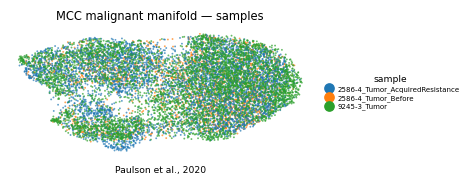

In [ ]:
# save sample-integration figure on the house linear layout (single panel + external legend)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xy = plot.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.7, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.3, fontsize=4.6, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('MCC malignant manifold — samples', size=7.5)
ax.text(.5, -.13, 'Paulson et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])